<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Customer data
df = pd.DataFrame({
    "Annual_Income": [15, 18, 20, 22, 25, 40, 42, 45, 48, 50,
                      70, 75, 78, 82, 85],
    "Spending_Score": [20, 25, 18, 30, 28, 45, 50, 42, 55, 48,
                       75, 80, 72, 85, 78]
})

df.head()

,Annual_Income,Spending_Score
0,15,20
1,18,25
2,20,18
3,22,30
4,25,28


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [3]:
inertias = []
k_values = range(1,9)

for k in k_values:
  model = KMeans(
      n_clusters=k,
      init="k-means++",
      n_init=10,
      random_state=42
  )

  model.fit(X_scaled)
  inertias.append(model.inertia_)

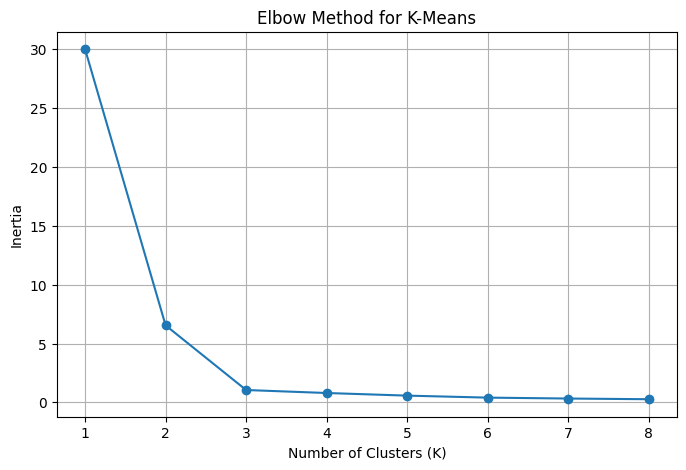

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:
from sklearn.metrics import silhouette_score

for k in range(2,9):
  model = KMeans(
      n_clusters=k,
      init = "k-means++",
      n_init=10,
      random_state=42
  )

  labels = model.fit_predict(X_scaled)

  score = silhouette_score(X_scaled,labels)
  print(score)

0.6695148681336849
0.7504940096924523
0.5986880288782154
0.4923772453915321
0.35127433653580836
0.3089363908326025
0.2584328013997333


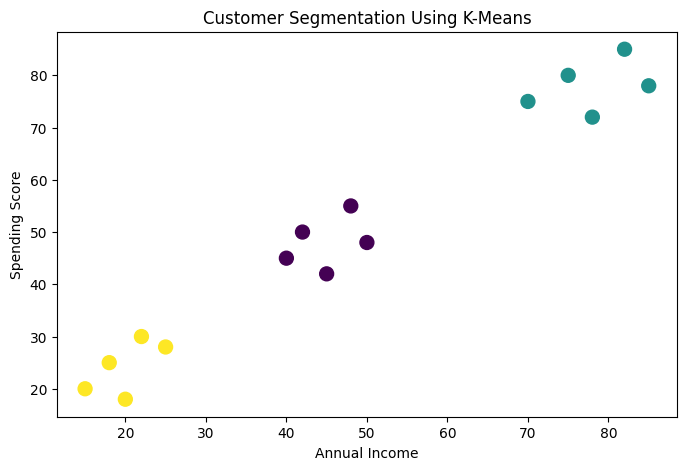

In [8]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation Using K-Means")
plt.show()

In [9]:
df.groupby("Cluster")[["Annual_Income", "Spending_Score"]].mean().round(2)

,Annual_Income,Spending_Score
Cluster,,
0,45.0,48.0
1,78.0,78.0
2,20.0,24.2
